# 14. Итоговая таблица погодных признаков на C40

Основной сценарий согласован пользователем: давность METAR до 60 минут,
предполагаемая задержка 15 минут, COR сохранены с флагом, без импутации.
Выбирается последнее сообщение со строго предшествующим условным временем
доступности. Выбор не зависит от качества или исхода, более старое «хорошее»
сообщение не подставляется. Фактическое время получения исторических METAR,
включая исправления COR, не подтверждено.

Все строки посадок и исходные числа сохраняются. Модельные копии `_model`
ограничены временной доступностью, проверкой основного текста и принятыми
числовыми масками. Наличие таблицы не означает завершенное обучение или
готовый эксплуатационный прогноз.


In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from html import escape
from cycler import cycler

BASE = Path.cwd().resolve()
while not (BASE / 'reports/03_pilot_manifest.json').exists():
    if BASE == BASE.parent:
        raise FileNotFoundError('Не найдена папка europe/weather с выполненным пилотом')
    BASE = BASE.parent
PROJECT = BASE.parents[1]
R, F, DATA = BASE / 'reports', BASE / 'figures', BASE / 'data'
F.mkdir(exist_ok=True)
sys.path.insert(0, str(BASE / 'scripts'))
manifest = json.loads((R / '03_pilot_manifest.json').read_text(encoding='utf8'))
def sha(path):
    with path.open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()
assert sha(PROJECT / 'europe/data/analytical/06_05_cases_excluded.parquet') == manifest['input_sha256']
for source in manifest['downloads']:
    path = DATA / 'raw' / f"{source['airport']}_{source['month']}.csv"
    assert sha(path) == source['sha256']

GREEN, CORAL, LIGHT_GREEN, LIGHT_CORAL = '#00897B', '#D65A4A', '#80CBC4', '#E69A90'
plt.rcParams.update({'figure.dpi':120, 'font.size':11, 'axes.spines.top':False,
    'axes.spines.right':False, 'axes.grid':True, 'grid.alpha':.16,
    'axes.prop_cycle':cycler(color=[CORAL, GREEN, LIGHT_CORAL, LIGHT_GREEN])})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_colwidth', 100)
def save(name):
    plt.tight_layout()
    for ext in ['png', 'svg']:
        plt.savefig(F / f'{name}.{ext}', bbox_inches='tight')
    plt.show()
def readable_table(frame):
    html = frame.to_html(index=False, escape=True)
    display(HTML('<div style="max-width:100%;overflow:auto">' + html + '</div>'))


,version,rows,go_arounds,input_sha256,all_source_rows_present_once,events_and_labels_unchanged,source_reports_unchanged,strict_assumed_availability_before_c40,max_age_minutes,assumed_latency_minutes,...,imputation,availability_verified,numeric_mask_registry_preserved,numeric_flagged_rows,numeric_masked_cells,rows_deleted,training_executed,temporal_split_assigned,created_utc,implementation_sha256
0,final-c40-weather-v1,6331485,18349,1111c7480ff7615042a332c586c8f60459bf5d6000da11ea4d0ec2a773fc0719,True,True,True,True,60,15,...,False,False,True,50,96,0,False,False,2026-10-10T21:43:27.277710+00:00,3e71c8b6966fbbba25784ce19974ad23c0bd4aac68a0c111c79f420c488c034a


GoA,rows,observation_usable,weather_core_usable,cor_usable,numeric_flagged_rows
False,6313136,6305612,6304267,274146,50
True,18349,18326,18319,1040,0


field,rows,present_model,present_percent
cavok,6331485,6322586,99.859448
cloud_amount_unavailable,6331485,6322586,99.859448
cloud_ceiling_ft,6331485,2145838,33.891544
cloud_ceiling_relation,6331485,6322586,99.859448
cloud_ceiling_status,6331485,6322586,99.859448
cloud_type_unavailable,6331485,6322586,99.859448
cumulonimbus_reported,6331485,6322586,99.859448
dewpoint_c,6331485,6322433,99.857032
gust_group_reported,6331485,6322586,99.859448
lowest_known_cloud_base_ft,6331485,3696828,58.388009


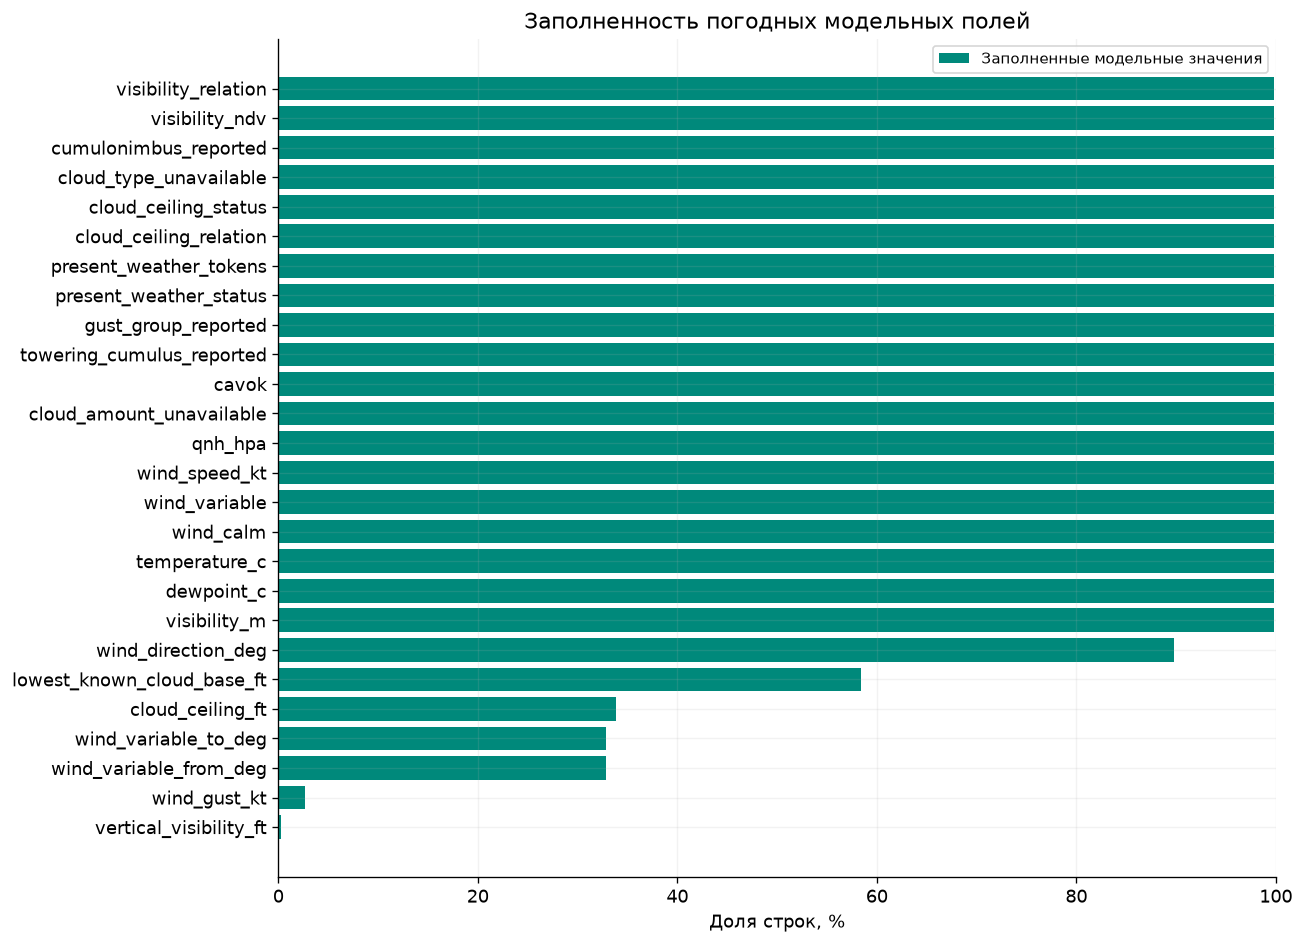

In [2]:
protocol=json.loads((R/'22_final_weather_protocol.json').read_text(encoding='utf8'))
application=json.loads((R/'23_final_weather_application.json').read_text(encoding='utf8'))
coverage=pd.read_csv(R/'23_final_weather_coverage.csv')
fields=pd.read_csv(R/'23_final_weather_fields.csv')
assert protocol['assumed_latency_minutes']==application['assumed_latency_minutes']==15
assert application['rows']==coverage.rows.sum()==6331485
assert coverage.loc[coverage.GoA.eq(True),'rows'].sum()==application['go_arounds']==18349
assert application['all_source_rows_present_once'] and application['events_and_labels_unchanged']
assert application['source_reports_unchanged'] and application['numeric_mask_registry_preserved']
assert application['strict_assumed_availability_before_c40']
assert not application['training_executed'] and application['rows_deleted']==0
display(pd.DataFrame([{k:v for k,v in application.items() if k!='files'}]))
readable_table(coverage.groupby('GoA')[['rows','observation_usable','weather_core_usable','cor_usable','numeric_flagged_rows']].sum().reset_index())
filled=fields.groupby('field')[['rows','present_model']].sum()
filled['present_percent']=100*filled.present_model/filled.rows
readable_table(filled.reset_index())
fig,ax=plt.subplots(figsize=(11,8))
ordered=filled.present_percent.sort_values()
ax.barh(ordered.index,ordered.values,color=GREEN,label='Заполненные модельные значения')
ax.set(xlabel='Доля строк, %',xlim=(0,100),title='Заполненность погодных модельных полей')
ax.legend(fontsize=9)
save('34_final_weather_completeness')


## Независимая проверка времени выбора

Для всех файлов последний допустимый отчет повторно определяется через
поиск позиции в массиве времен наблюдения (numpy.searchsorted), независимо
от использованного при сборке merge_asof. Проверяются источники, SHA-256,
кратность строк, ограничения доступности и заполненность вне допустимого
основного блока. Неоднозначные времена проверены отдельно.


In [3]:
seen=np.zeros(application['rows'],dtype=bool)
labels=0
examples=[]
for item in application['files']:
    path=DATA/'final_c40_weather_v1'/item['name']
    assert sha(path)==item['sha256']
    frame=pd.read_parquet(path)
    key=item['name'].removesuffix('.parquet')
    reports=pd.read_parquet(DATA/'full_cloud_v2/reports'/f'{key}_reports.parquet')
    assert sha(DATA/'full_cloud_v2/reports'/f'{key}_reports.parquet')==item['source_reports_sha256']
    assert not reports.duplicated('metar_utc',keep=False).any()
    ordered=reports.sort_values('metar_utc')
    available_ns=(ordered.metar_utc+pd.Timedelta(minutes=15)).astype('int64').to_numpy()
    positions=np.searchsorted(available_ns,frame.C40_CROSS_TIME.astype('int64').to_numpy(),side='left')-1
    has=positions>=0
    assert frame.metar_utc.notna().to_numpy().tolist()==has.tolist()
    expected=ordered.metar_id.to_numpy()[positions[has]]
    assert np.array_equal(frame.loc[has,'metar_id'].to_numpy(),expected)
    ids=frame.source_row.to_numpy()
    assert frame.source_row.is_unique and not seen[ids].any()
    seen[ids]=True
    labels+=int(frame.GoA.sum())
    assert frame.loc[has,'assumed_available_utc'].lt(frame.loc[has,'C40_CROSS_TIME']).all()
    assert frame.loc[frame.weather_core_usable,'age_minutes'].between(15,60,inclusive='right').all()
    model_fields=[f for f in frame if f.endswith('_model')]
    assert frame.loc[~frame.weather_core_usable,model_fields].isna().all().all()
    for name in model_fields:
        source=name.removesuffix('_model')
        mask=frame.numeric_mask_fields.str.split(';').apply(lambda values:source in values)
        assert frame.loc[mask,name].isna().all()
    if len(examples)<5:
        examples.append(frame[['source_row','airport','GoA','C40_CROSS_TIME','metar_utc','assumed_available_utc',
            'age_minutes','correction_reported','weather_core_usable','weather_missing_reason','qnh_hpa','qnh_hpa_model']].head(2))
assert seen.all() and labels==18349
assert sha(PROJECT/'europe/data/analytical/06_05_cases_excluded.parquet')==application['input_sha256']
readable_table(pd.concat(examples,ignore_index=True))
display(pd.DataFrame([{'Независимо проверено файлов':len(application['files']),
    'Строк сохранено':len(seen),'GoA сохранено':labels,'Выбор последнего допустимого METAR проверен':True}]))


source_row,airport,GoA,C40_CROSS_TIME,metar_utc,assumed_available_utc,age_minutes,correction_reported,weather_core_usable,weather_missing_reason,qnh_hpa,qnh_hpa_model
176,EDDB,False,2019-01-01 05:31:22+00:00,2019-01-01 04:50:00+00:00,2019-01-01 05:05:00+00:00,41.366667,False,True,,1020.0,1020.0
343,EDDB,False,2019-01-01 06:41:25+00:00,2019-01-01 06:20:00+00:00,2019-01-01 06:35:00+00:00,21.416667,False,True,,1018.0,1018.0
2172398,EDDB,False,2020-01-01 04:55:03+00:00,2020-01-01 04:20:00+00:00,2020-01-01 04:35:00+00:00,35.050000,False,True,,1033.0,1033.0
2172485,EDDB,False,2020-01-01 05:42:41+00:00,2020-01-01 05:20:00+00:00,2020-01-01 05:35:00+00:00,22.683333,False,True,,1033.0,1033.0
3095999,EDDB,False,2021-01-01 05:58:13+00:00,2021-01-01 05:20:00+00:00,2021-01-01 05:35:00+00:00,38.216667,False,True,,1005.0,1005.0
3096138,EDDB,False,2021-01-01 08:26:16+00:00,2021-01-01 07:50:00+00:00,2021-01-01 08:05:00+00:00,36.266667,False,True,,1006.0,1006.0
4165233,EDDB,False,2022-01-01 06:03:23+00:00,2022-01-01 05:20:00+00:00,2022-01-01 05:35:00+00:00,43.383333,False,True,,1019.0,1019.0
4165266,EDDB,False,2022-01-01 06:16:07+00:00,2022-01-01 05:50:00+00:00,2022-01-01 06:05:00+00:00,26.116667,False,True,,1020.0,1020.0
5785020,EDDB,False,2023-01-01 05:10:18+00:00,2023-01-01 04:50:00+00:00,2023-01-01 05:05:00+00:00,20.300000,False,True,,1012.0,1012.0
5785128,EDDB,False,2023-01-01 06:04:15+00:00,2023-01-01 05:20:00+00:00,2023-01-01 05:35:00+00:00,44.250000,False,True,,1012.0,1012.0


,Независимо проверено файлов,Строк сохранено,GoA сохранено,Выбор последнего допустимого METAR проверен
0,93,6331485,18349,True


## Пропуски, флаги и границы применения

Причины пропуска различаются: нет предшествующего METAR, сообщение слишком
старое, неоднозначное время, непроверенный основной текст, числовая маска,
отсутствующая группа или неизвестная характеристика в самом сообщении.
COR означает исправленную версию; True у correction_reported не доказывает
фактическую доступность исправления на C40. Правила объяснены в README.

В модельных полях остаются отношения ге/меньше для специальных кодов видимости,
отдельная вертикальная видимость и статусы пропусков. Ветер относительно ВПП
не рассчитывается: выбор ВПП к C40 не установлен. Аэропорт назначения заранее
известен по исследовательскому допущению пользователя, не по доказанному
свойству ретроспективного поля airport.

Метка GoA и служебные поля происхождения не входят в список погодных
предикторов. Импутация, статистические преобразования, подбор признаков и
оценка модели выполняются только по отдельному протоколу моделирования.
[Итоговый отчет](../reports/23_final_weather_review.md).


## Временное разделение

Согласовано разделение по C40 в UTC: train до 2022 года, validation за 2022
год, test за 2023 год. Карта хранится отдельно в data/temporal_split_v1/.
Поле temporal_split в погодном снимке содержит прежний служебный заполнитель;
перед присоединением карты его необходимо удалить. Присоединение выполняется
по source_row с проверкой one_to_one и неизменного хеша входной базы.
Test уже использовался в предыдущих исследованиях и не является новой
независимой подтверждающей оценкой. Обучение не выполнялось.


In [4]:
split_application=json.loads((R/'24_temporal_split_application.json').read_text(encoding='utf8'))
split_counts=pd.read_csv(R/'24_temporal_split_counts.csv')
split_seen=np.zeros(application['rows'],dtype=bool)
for item in split_application['files']:
    path=DATA/'temporal_split_v1'/item['name']
    assert sha(path)==item['sha256']
    mapping=pd.read_parquet(path)
    years=mapping.C40_CROSS_TIME.dt.year
    expected=np.select([years.lt(2022),years.eq(2022)],['train','validation'],default='test')
    assert np.array_equal(mapping.temporal_split.to_numpy(),expected)
    assert mapping.source_row.is_unique and not split_seen[mapping.source_row].any()
    split_seen[mapping.source_row]=True
assert split_seen.all() and split_counts.rows.sum()==application['rows']
readable_table(split_counts.groupby('temporal_split').rows.sum().reset_index())
readable_table(split_counts.groupby(['temporal_split','airport']).rows.sum().reset_index())


temporal_split,rows
test,546577
train,4165060
validation,1619848


temporal_split,airport,rows
test,EDDB,20511
test,EDDF,11521
test,EDDM,43247
test,EGLL,72121
test,EGSS,21930
test,EHAM,11615
test,EIDW,32534
test,EKCH,3647
test,EPWA,19600
test,ESSA,23351
